# Figure 7 — observed shapes compared with native NISP

This is the single active Figure 7 notebook, replacing the former 7 and 7b.
The main figure compares ellipticity errors relative to observed JWST for diffusion,
ResNet and ResNet-D5. Blue model contours and orange native-NISP contours enclose
the same probabilities (68% and 95%); identical native contours repeat in each column.
A horizontal zero line makes the error width and offsets visible. The earlier
agreement/hexbin view is preserved as v02 in `exports/` and `revisions/`. The companion
summary retains interpolation baselines, mean-of-three diffusion, adaptive moments,
and full-population measurement success.

The frozen Figure 6 predictions and existing JWST/model measurements are unchanged.
Native NISP is measured on its original grid, with the same angular aperture and
Gaussian weight (pixel step 5). Native uses its own validity mask; cached images
retain their common-valid mask. Each estimator uses the intersection of successful
JWST, native NISP and all six cached methods. No source-segmentation clipping,
PSF matching, inference, or test-set access. These are observed cross-band shapes,
not PSF-corrected shapes or calibrated shear.

Rebuild the versioned input with `python code/add_native_shape_comparison.py`
from the repository root in a fresh checkout without the v02 bundle/output directory.
The analyzer saves its contract and source snapshots before measuring native images.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.lines import Line2D
from IPython.display import display
here=Path.cwd();workspace=here if (here/'figure_utils.py').exists() else here/'paper_figures'
if str(workspace) not in sys.path:sys.path.insert(0,str(workspace))
from figure_utils import ROOT,FIGURES,COLORS,style,read_json,sha,export
%matplotlib inline
style()
VERSION='v03'
DATA_VERSION='v02'
path=FIGURES/'inputs'/f'cached_shapes_{DATA_VERSION}.json'
b=read_json(path)
assert b['complete'] and b['local_only']
assert sha(ROOT/b['arrays_path'])==b['arrays_sha256']
with np.load(ROOT/b['arrays_path']) as f:arrays={k:f[k] for k in f.files}
names=b['methods'];labels={'native':'Native NISP','bilinear':'Bilinear','bicubic':'Bicubic','diffusion':'Diffusion (1 sample)',
'diffusion_mean3':'Diffusion (mean of 3)','legacy':'ResNet','direct5':'ResNet-D5'}
colors={**COLORS,'diffusion_mean3':'#B485B8'}
print('Attempted:',len(b['object_ids']),'Common across both estimators:',b['cross_estimator_objects'])


Attempted: 2118 Common across both estimators: 1297


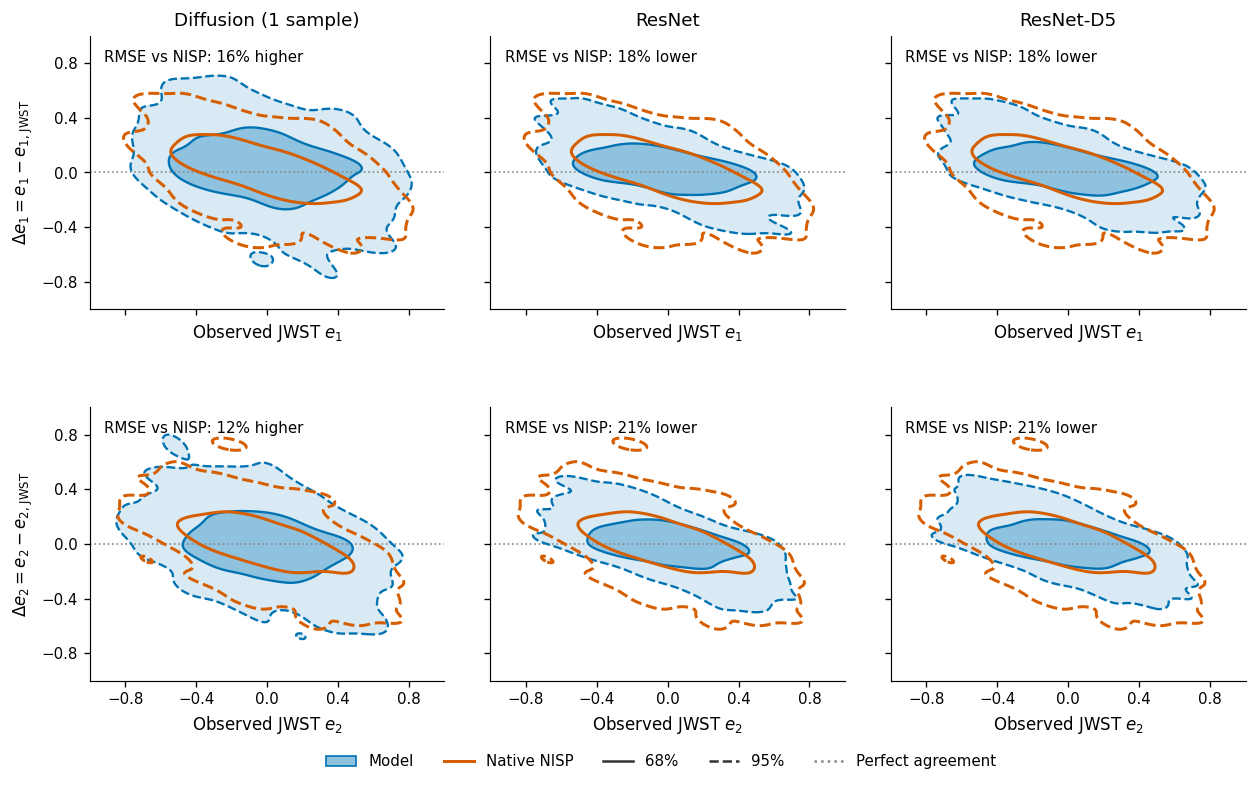

Exported: fig07_model_shape_residuals_v03.pdf, fig07_model_shape_residuals_v03.svg, fig07_model_shape_residuals_v03.png


In [2]:
# Main Figure 7: compare equal-probability regions in shape-error coordinates.
from scipy.stats import gaussian_kde
from matplotlib.patches import Patch
style(10)
a=arrays
keep=np.isin(a['object_ids'],b['summaries']['fixed']['object_ids'])
ref=a['fixed__target__e'][keep]

def probability_levels(density):
    ordered=np.sort(density.ravel())[::-1]
    cumulative=np.cumsum(ordered)/ordered.sum()
    # Return [95%,68%], the increasing density levels required by contour.
    levels=np.array([ordered[np.searchsorted(cumulative,p)] for p in [.95,.68]])
    for level,p in zip(levels,[.95,.68]):
        assert abs(density[density>=level].sum()/density.sum()-p)<.002
    return levels

axis=np.linspace(-2,2,401);xx,yy=np.meshgrid(axis,axis)
densities={}
for m in ['native','diffusion','legacy','direct5']:
 pred=a[f'fixed__{m}__e'][keep]
 for k in range(2):
  values=np.array([ref[:,k],pred[:,k]-ref[:,k]])
  density=gaussian_kde(values)(np.array([xx.ravel(),yy.ravel()])).reshape(xx.shape)
  densities[m,k]=(density,probability_levels(density))
fig,axes=plt.subplots(2,3,figsize=(10.7,6.8),sharex=True,sharey=True)
blue='#0072B2';orange='#D55E00'
for j,m in enumerate(['diffusion','legacy','direct5']):
 for k in range(2):
  ax=axes[k,j];d,levels=densities[m,k]
  ax.contourf(axis,axis,d,levels=[*levels,d.max()+1],colors=['#D9EAF4','#8EC2DF'],zorder=1)
  ax.axhline(0,color='#888',ls=':',lw=1,zorder=2)
  ax.contour(axis,axis,d,levels=levels,colors=blue,linestyles=['--','-'],linewidths=1.4,zorder=3)
  nd,nl=densities['native',k]
  ax.contour(axis,axis,nd,levels=nl,colors=orange,linestyles=['--','-'],linewidths=1.8,zorder=4)
  ax.set_xlim(-1,1);ax.set_ylim(-1,1)
  ax.set_xticks([-.8,-.4,0,.4,.8]);ax.set_yticks([-.8,-.4,0,.4,.8])
  gain=b['native_comparison']['fixed'][m]['reduction_percent'][k+1]
  word='lower' if gain>0 else 'higher'
  ax.text(.04,.95,f'RMSE vs NISP: {abs(gain):.0f}% {word}',transform=ax.transAxes,va='top',fontsize=9)
  if k==0:ax.set_title({'diffusion':'Diffusion (1 sample)','legacy':'ResNet','direct5':'ResNet-D5'}[m])
  if j==0:ax.set_ylabel(rf'$\Delta e_{k+1}=e_{k+1}-e_{{{k+1},\,\mathrm{{JWST}}}}$')
  ax.set_xlabel(rf'Observed JWST $e_{k+1}$')
fig.subplots_adjust(left=.085,right=.985,top=.93,bottom=.14,wspace=.13,hspace=.36)
fig.legend(handles=[Patch(facecolor='#8EC2DF',edgecolor=blue,label='Model'),Line2D([],[],color=orange,lw=1.8,label='Native NISP'),Line2D([],[],color='#333',ls='-',label='68%'),Line2D([],[],color='#333',ls='--',label='95%'),Line2D([],[],color='#888',ls=':',label='Perfect agreement')],loc='lower center',ncol=5,frameon=False,bbox_to_anchor=(.53,.015))

# All measurements enter the KDE and RMSE, including rare residuals beyond the
# displayed [-1,1] range. The contours show probability regions, not all points.
for (method,component),(density,levels) in densities.items():
    assert abs(density.sum()*(axis[1]-axis[0])**2-1)<.001
    assert density[np.abs(axis)>1,:].max()<levels[0], 'Displayed y range clips a contour'
contour_settings=dict(coordinates='x=observed JWST e; y=method e minus JWST e',
    methods=['native','diffusion','legacy','direct5'],probabilities=[.68,.95],
    smoothing='Gaussian KDE, Scott bandwidth, for each method/component; same sample size',
    evaluation_grid='401x401 over [-2,2] on both axes',display_limits=[-1,1],
    population='Same fixed-moment common-success sample from frozen cached_shapes_v02',
    model_style='Blue filled 68% and 95% regions; solid 68%, dashed 95%',
    native_style='Orange outlines; identical native contours across each row',
    outside_display_counts={m:np.sum(np.abs(a[f'fixed__{m}__e'][keep]-ref)>1,axis=0).tolist()
                            for m in ['native','diffusion','legacy','direct5']})
plt.show()
export(fig,f'fig07_model_shape_residuals_{VERSION}','07_model_shapes.ipynb',
       [path,ROOT/b['arrays_path']],
       dict(estimator='fixed',objects=int(keep.sum()),contours=contour_settings,gain=b['gain']),
       status='Figure 7: model and native NISP ellipticity residual probability contours')
style()


## Figure 7 caption

Observed ellipticity residuals relative to JWST F115W for diffusion (one sample),
ResNet and ResNet-D5; $e_1$ is shown above and $e_2$ below. The horizontal axis is
observed JWST ellipticity and the vertical axis is $\Delta e=e-e_{\mathrm{JWST}}$.
Blue regions show the model's joint residual distribution, with orange native-NISP
contours repeated across each row. Solid and dashed boundaries enclose 68% and 95%
of each smoothed joint distribution. The dotted horizontal line is zero error.
Both model and native contours use Gaussian KDE with Scott bandwidth and the same
1,446 successful objects; their probability levels are calculated separately.

Fixed Gaussian-weighted moments use the same angular window on native and
reconstructed grids. All comparisons use galaxies measurable in JWST, native
NISP and all six cached methods, out of 2,118 attempted validation fields.
Annotations give the change in per-component RMSE relative to native NISP.
All objects enter the density estimates and RMSE, including rare residuals outside
the displayed [-1,1] range. These are joint probability regions, not confidence
bands or conditional intervals at a given JWST ellipticity. Full-population success
and paired spatial-block uncertainty appear below. Observed cross-band shapes
include instrumental PSF and pixel-sampling differences; they are not calibrated
shear estimates.

In [3]:
print(f"Figure 7: {b['summaries']['fixed']['common_successes']:,} common successful objects / {len(b['object_ids']):,} attempted.")
rows=[]
for case in ['fixed','adaptive']:
    for name in ['native','diffusion','legacy','direct5']:
        rec=b['native_comparison'][case][name]
        rows.append(dict(estimator=case,method=labels[name],
            common_objects=b['summaries'][case]['common_successes'],
            successful_of_2118=b['summaries'][case]['success_counts'][name],
            component_rmse=rec['rmse'][0],gain_percent=rec['reduction_percent'][0],
            gain_ci95_percent=rec['ci95_percent'][0]))
display(pd.DataFrame(rows))


Figure 7: 1,446 common successful objects / 2,118 attempted.


,estimator,method,common_objects,successful_of_2118,component_rmse,gain_percent,gain_ci95_percent
0,fixed,Native NISP,1446,1741,0.201114,0.000000,"[0.0, 0.0]"
1,fixed,Diffusion (1 sample),1446,1633,0.228958,-13.844969,"[-16.03157423277367, -11.26577964635931]"
2,fixed,ResNet,1446,1786,0.162364,19.267582,"[16.591509333536603, 21.87278368654546]"
3,fixed,ResNet-D5,1446,1786,0.162494,19.203084,"[16.520554995929015, 21.64788704880936]"
4,adaptive,Native NISP,1498,1685,0.242377,0.000000,"[0.0, 0.0]"
5,adaptive,Diffusion (1 sample),1498,1678,0.296577,-22.362146,"[-27.807251658056707, -17.97281253539561]"
6,adaptive,ResNet,1498,1742,0.216657,10.611569,"[7.3468183709684, 13.219594509871527]"
7,adaptive,ResNet-D5,1498,1745,0.216849,10.532413,"[7.611552589936058, 13.020338502896005]"


## Companion diagnostic: both estimators and all attempted measurements

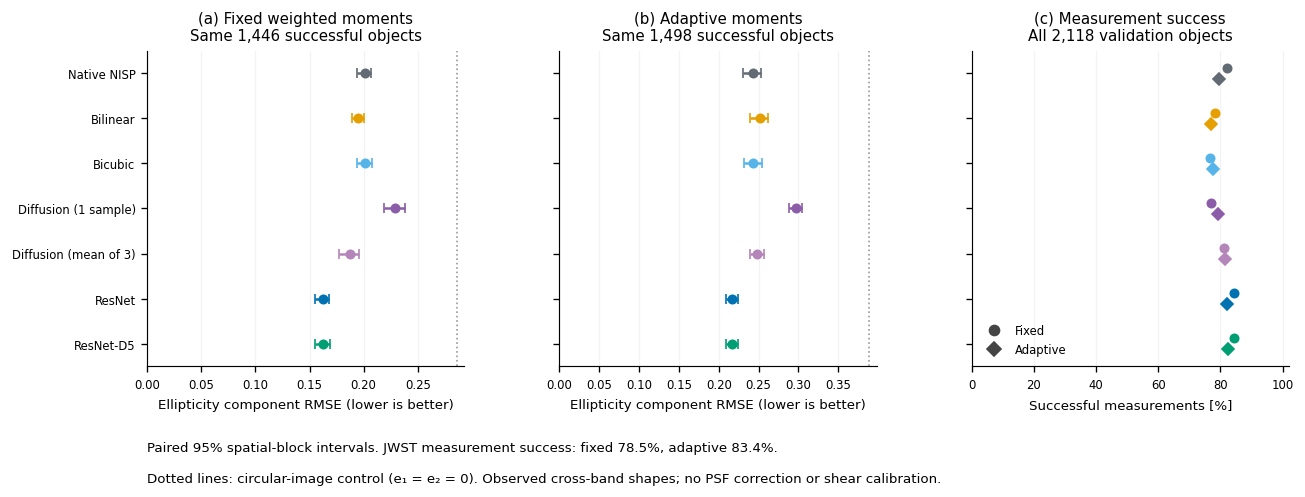

Exported: fig07_model_shapes_v03.pdf, fig07_model_shapes_v03.svg, fig07_model_shapes_v03.png


[PosixPath('/home/shemmati/Work/Projects/superNISP/paper_figures/exports/fig07_model_shapes_v03.pdf'),
 PosixPath('/home/shemmati/Work/Projects/superNISP/paper_figures/exports/fig07_model_shapes_v03.svg'),
 PosixPath('/home/shemmati/Work/Projects/superNISP/paper_figures/exports/fig07_model_shapes_v03.png')]

In [4]:
fig,axes=plt.subplots(1,3,figsize=(11.6,4.7),sharey=True)
y=np.arange(len(names))
for ax,case,title in zip(axes[:2],['fixed','adaptive'],['(a) Fixed weighted moments','(b) Adaptive moments']):
    summary=b['summaries'][case]
    for i,name in enumerate(names):
        rec=summary['methods'][name]['component_rmse'];value=rec['mean'];lo,hi=rec['ci95']
        ax.errorbar(value,i,xerr=np.array([[value-lo],[hi-value]]),fmt='o',color=colors[name],capsize=3,ms=5)
    control=summary['methods']['round_control']['component_rmse']['mean']
    ax.axvline(control,color='#999999',ls=':',lw=1)
    ax.set_xlim(left=0)
    ax.set_xlabel('Ellipticity component RMSE (lower is better)')
    ax.set_title(f"{title}\nSame {summary['common_successes']:,} successful objects")
axes[0].set_yticks(y,[labels[m] for m in names])
for case,marker,offset in [('fixed','o',-.12),('adaptive','D',.12)]:
    for i,name in enumerate(names):
        fraction=100*b['summaries'][case]['success_counts'][name]/len(b['object_ids'])
        axes[2].plot(fraction,i+offset,marker,color=colors[name],ms=5)
axes[2].set_title('(c) Measurement success\nAll 2,118 validation objects')
axes[2].set_xlim(0,102);axes[2].set_xlabel('Successful measurements [%]')
axes[2].legend(handles=[Line2D([],[],color='#444444',marker='o',ls='',label='Fixed'),Line2D([],[],color='#444444',marker='D',ls='',label='Adaptive')],loc='lower left',frameon=False)
for ax in axes:
    ax.set_ylim(len(names)-.5,-.5);ax.grid(axis='x',alpha=.15)
fig.subplots_adjust(left=.17,right=.99,top=.81,bottom=.25,wspace=.3)
fixed_ref=100*b['summaries']['fixed']['success_counts']['target']/len(b['object_ids'])
adaptive_ref=100*b['summaries']['adaptive']['success_counts']['target']/len(b['object_ids'])
fig.text(.17,.10,f'Paired 95% spatial-block intervals. JWST measurement success: fixed {fixed_ref:.1f}%, adaptive {adaptive_ref:.1f}%.',fontsize=8)
fig.text(.17,.045,'Dotted lines: circular-image control (e₁ = e₂ = 0). Observed cross-band shapes; no PSF correction or shear calibration.',fontsize=8)
plt.show()
export(fig,f'fig07_model_shapes_{VERSION}','07_model_shapes.ipynb',[path],
       dict(population=b['population'],fixed=b['fixed'],adaptive=b['adaptive'],summary=b['summary']),
       status='Local matched observed-shape comparison and full-denominator measurement success')


In [5]:
rows=[]
for population,summaries in [('Per-estimator common',b['summaries']),('Both estimators common',b['cross_estimator_common'])]:
    for estimator,summary in summaries.items():
        for name in names:
            rec=summary['methods'][name]
            rows.append(dict(population=population,estimator=estimator,objects=summary['common_successes'],method=labels[name],
                component_rmse=rec['component_rmse']['mean'],ci95=rec['component_rmse']['ci95'],bias_e1=rec['bias']['mean'][0],bias_e2=rec['bias']['mean'][1],
                large_error_fraction=rec['vector_error_above_0_2_fraction']['mean']))
display(pd.DataFrame(rows))


,population,estimator,objects,method,component_rmse,ci95,bias_e1,bias_e2,large_error_fraction
0,Per-estimator common,fixed,1446,Native NISP,0.201114,"[0.19428294814922256, 0.2071313152267453]",0.011173,-0.000405,0.376902
1,Per-estimator common,fixed,1446,Bilinear,0.195218,"[0.1892041880685358, 0.2004383864028548]",0.010785,0.000455,0.399723
2,Per-estimator common,fixed,1446,Bicubic,0.201446,"[0.19418894795282546, 0.2078456160897296]",0.010564,-0.000530,0.374827
3,Per-estimator common,fixed,1446,Diffusion (1 sample),0.228958,"[0.2184291798724818, 0.23781131310163514]",0.032180,-0.015698,0.429461
4,Per-estimator common,fixed,1446,Diffusion (mean of 3),0.187511,"[0.17752315863011217, 0.19618020484332216]",0.031907,-0.015020,0.352006
5,Per-estimator common,fixed,1446,ResNet,0.162364,"[0.15529346190828233, 0.16839012022839078]",0.017356,-0.000945,0.286307
6,Per-estimator common,fixed,1446,ResNet-D5,0.162494,"[0.1554486054894158, 0.16864597053879055]",0.019325,-0.000040,0.286307
7,Per-estimator common,adaptive,1498,Native NISP,0.242377,"[0.23029156356561614, 0.2531584123270412]",0.010843,-0.006433,0.550734
8,Per-estimator common,adaptive,1498,Bilinear,0.251618,"[0.23924230763094992, 0.2620319609871056]",0.012356,-0.003585,0.598798
9,Per-estimator common,adaptive,1498,Bicubic,0.243203,"[0.23100338883495103, 0.25406251889347065]",0.010900,-0.006499,0.560748


## Interpretation limits

The error bars condition on each estimator's matched successful sample. Report
full-population success fractions with the shape errors, and inspect the stricter
intersection across both estimators. Fixed and adaptive shapes use different
weights, so their absolute RMSE values have different targets. Galaxies in a
blend may contaminate both measurements; the adaptive centroid guard is not a
deblender. Mean-of-three refers to a mean image, not averaged ellipticity draws.
This cache cannot establish diffusion realization-to-realization shape scatter.
